# Quality-dip screen: visual EDA (educational research, not investment advice)

This notebook explores the dashboard's data of **2026-11-04** (288 US and European stocks). Everything here describes the screen's results and
the history of the rule, in this sample. Nothing here predicts returns or says what to do.

How to read each section: **intuition first, then the formula, then code, with a worked number.**
Data files are in `data/` (see `DATA_DICTIONARY.md`). Figures are also saved to `figures/`.

Caveats that apply to every plot: the universe is *today's* large companies (survivorship bias); fundamentals are not point-in-time; European
bars dated 2026-11-04 were still forming when the data was pulled (column `partial_bar`).

In [1]:
import json, gzip
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREY = "#2366c9", "#d9772b", "#8a92a2"        # blue = up/neutral, orange = down: colour-blind safe, and signs are always shown too

s = pd.read_csv("data/stocks.csv")
print(s.shape, "rows x columns")
print("data dates:", s["asof"].value_counts().to_dict())
s[["ticker", "region", "sector", "ret_5d", "resid_5d", "beta", "quality_score", "setup"]].head()

(288, 40) rows x columns
data dates: {'2026-11-03': 168, '2026-11-04': 120}


## 1. What is in the universe?
**Intuition.** A screen is only as broad as the list it looks at. More names per sector make "N fallers in a sector" more meaningful.

{'Europe': 86, 'Nordic': 34, 'US': 168} total 288


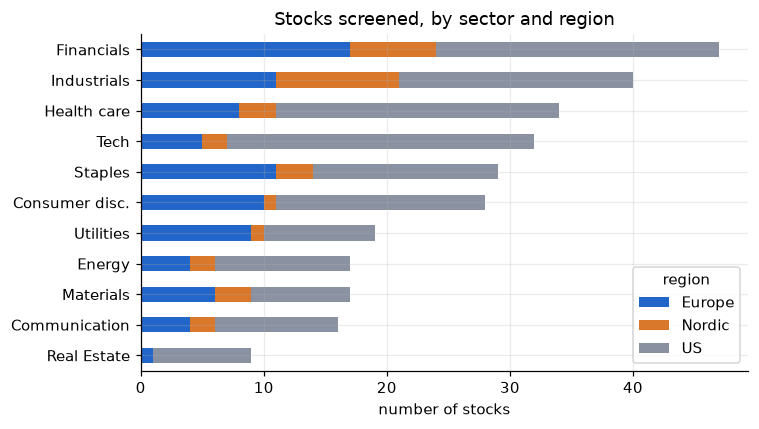

In [2]:
ct = pd.crosstab(s.sector, s.region)
ct = ct.loc[ct.sum(axis=1).sort_values().index]
ax = ct.plot.barh(stacked=True, figsize=(7, 4), color=[BLUE, ORANGE, GREY])
ax.set_title("Stocks screened, by sector and region"); ax.set_xlabel("number of stocks"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("figures/eda_universe.png"); plt.show()
print(ct.sum().to_dict(), "total", len(s))

## 2. Where do today's 5-day moves sit?
**Intuition.** If the whole distribution has shifted left, the market is selling off and a single stock's drop means less.
**Rule.** The default dip rule flags a 5-day fall of at least 7% (also: 1-day at least 4%, or 12% below the 20-day high).

median 5d +1.8%; 13 of 288 stocks are at or past the -7% rule


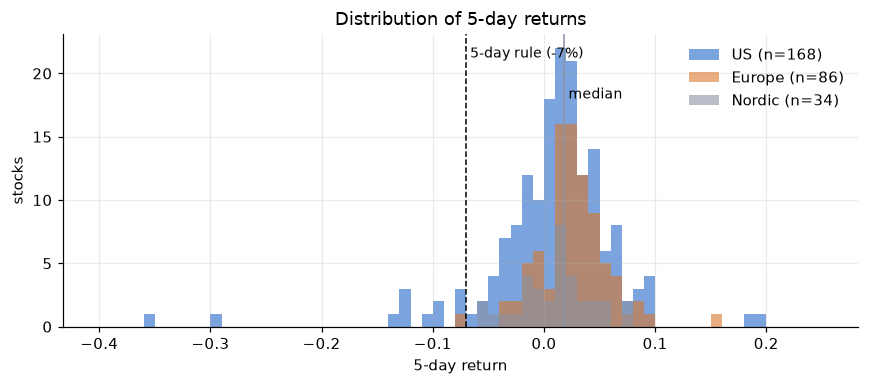

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(-0.40, 0.25, 66)
for reg, c in zip(["US", "Europe", "Nordic"], [BLUE, ORANGE, GREY]):
    ax.hist(s.loc[s.region == reg, "ret_5d"], bins=bins, alpha=0.6, label=f"{reg} (n={int((s.region == reg).sum())})", color=c)
ax.axvline(-0.07, color="k", ls="--", lw=1); ax.text(-0.07, ax.get_ylim()[1] * 0.92, " 5-day rule (-7%)", fontsize=9)
ax.axvline(s.ret_5d.median(), color=GREY, lw=1); ax.text(s.ret_5d.median(), ax.get_ylim()[1] * 0.78, " median", fontsize=9)
ax.set_xlabel("5-day return"); ax.set_ylabel("stocks"); ax.set_title("Distribution of 5-day returns"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/eda_5d_distribution.png"); plt.show()
print(f"median 5d {s.ret_5d.median():+.1%}; {int((s.ret_5d <= -0.07).sum())} of {len(s)} stocks are at or past the -7% rule")

## 3. Raw move vs market-adjusted move (the *residual*)
**Intuition.** If the whole index fell 2% and your stock fell 3%, most of the fall is the market. The residual strips out what the stock's own index
would explain, given how strongly the stock usually reacts to it (its *beta*).

**Formula.** `resid_5d = ret_5d - beta * index_5d`, where `index_5d = ret_5d - ret_5d_vs_index`.
Beta is the OLS slope of the stock's daily returns on its index's over the previous year (excluding the last 5 days), clipped to [0, 3].

**Worked example** (computed below from the data, GOOGL): the code recomputes the residual by hand and compares it with the stored value.

GOOGL: 5d return -12.65%, own index 5d -1.99%, beta 1.360
residual by hand = -0.1265 - 1.360 * -0.0199 = -0.0994   (stored: -0.0994)


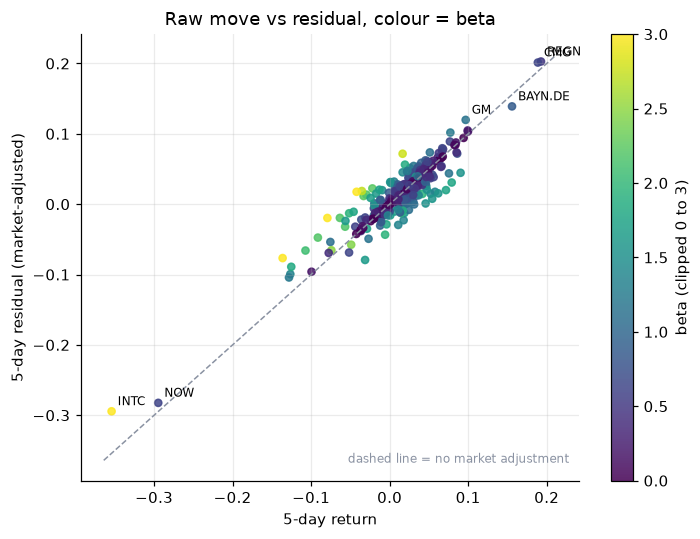

In [4]:
g = s[s.ticker == "GOOGL"].iloc[0]
idx5 = g.ret_5d - g.ret_5d_vs_index
print(f"GOOGL: 5d return {g.ret_5d:+.2%}, own index 5d {idx5:+.2%}, beta {g.beta:.3f}")
print(f"residual by hand = {g.ret_5d:+.4f} - {g.beta:.3f} * {idx5:+.4f} = {g.ret_5d - g.beta * idx5:+.4f}   (stored: {g.resid_5d:+.4f})")

fig, ax = plt.subplots(figsize=(6.6, 5))
sc = ax.scatter(s.ret_5d, s.resid_5d, c=s.beta, cmap="viridis", s=22, alpha=0.85)
lim = [min(s.ret_5d.min(), s.resid_5d.min()) - 0.01, max(s.ret_5d.max(), s.resid_5d.max()) + 0.01]
ax.plot(lim, lim, color=GREY, lw=1, ls="--"); ax.text(0.98, 0.04, "dashed line = no market adjustment", transform=ax.transAxes, fontsize=8, ha="right", color=GREY)
for _, r in s.reindex(s.resid_5d.abs().sort_values(ascending=False).index).head(6).iterrows():
    ax.annotate(r.ticker, (r.ret_5d, r.resid_5d), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("5-day return"); ax.set_ylabel("5-day residual (market-adjusted)"); ax.set_title("Raw move vs residual, colour = beta")
plt.colorbar(sc, label="beta (clipped 0 to 3)"); plt.tight_layout(); plt.savefig("figures/eda_residual.png"); plt.show()

## 4. How noisy are the betas?
**Intuition.** A beta from one year of one stock is an estimate with error (roughly plus or minus 0.2 to 0.3). A *negative* estimate for a large defensive
company is usually noise or a sector effect, so the screen floors it at 0 (no market adjustment). Values above 3 are capped at 3.

floored at 0: 49 | capped at 3: 4 | median raw beta 0.57
{'Europe': 0.8, 'Nordic': 0.86, 'US': 0.34} (median raw beta by region)


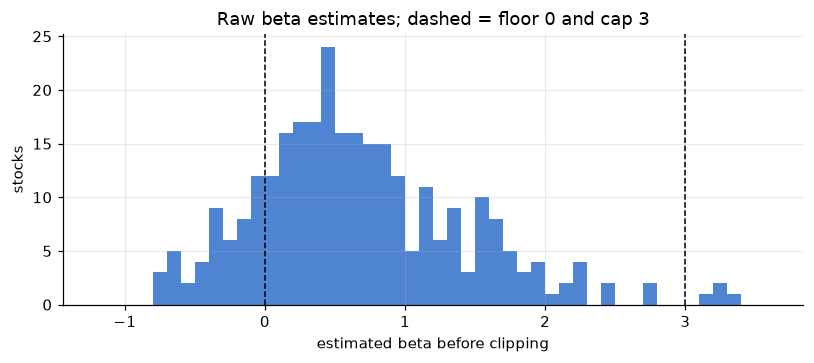

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(s.beta_raw, bins=np.linspace(-1.2, 3.6, 49), color=BLUE, alpha=0.8)
for x in (0, 3): ax.axvline(x, color="k", ls="--", lw=1)
ax.set_xlabel("estimated beta before clipping"); ax.set_ylabel("stocks"); ax.set_title("Raw beta estimates; dashed = floor 0 and cap 3")
plt.tight_layout(); plt.savefig("figures/eda_beta.png"); plt.show()
print("floored at 0:", int((s.beta_side == "floor").sum()), "| capped at 3:", int((s.beta_side == "cap").sum()), "| median raw beta", round(s.beta_raw.median(), 2))
print(s.groupby("region").beta_raw.median().round(2).to_dict(), "(median raw beta by region)")

## 5. Quality score: how much data stands behind it?
**Intuition.** The score is the share of checks passed (ROE, margin, debt, free cash flow, growth, size). Some checks do not apply to some sectors
(banks and insurers skip debt and free cash flow), and some are missing from the free data source. A score of 100 from 3 checks is weaker than 100 from 6.

score 100 with fewer than 4 checks scored: ['ABBV', 'MS', 'BLK', 'UBSG.SW', 'MAR']


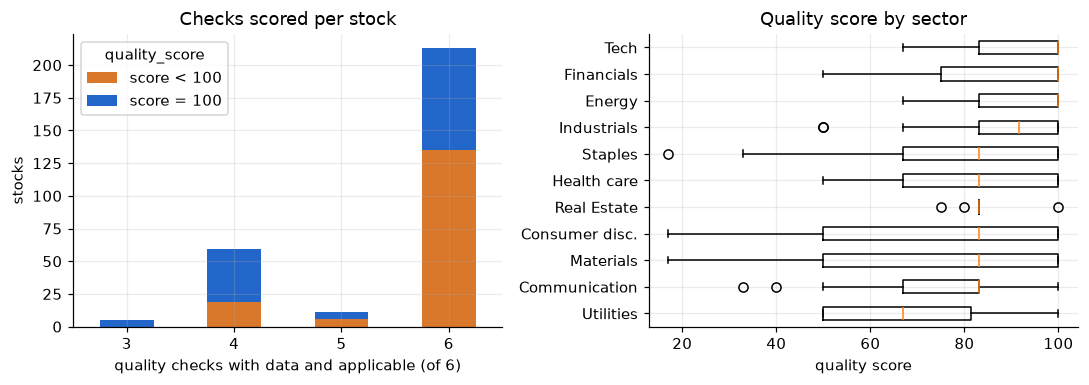

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
pd.crosstab(s.quality_checks_scored, s.quality_score >= 100).rename(columns={True: "score = 100", False: "score < 100"}).plot.bar(ax=axs[0], stacked=True, color=[ORANGE, BLUE], rot=0)
axs[0].set_title("Checks scored per stock"); axs[0].set_xlabel("quality checks with data and applicable (of 6)"); axs[0].set_ylabel("stocks")
order = s.groupby("sector").quality_score.median().sort_values().index
axs[1].boxplot([s.loc[s.sector == k, "quality_score"].dropna() for k in order], orientation="horizontal", tick_labels=order)
axs[1].set_title("Quality score by sector"); axs[1].set_xlabel("quality score")
plt.tight_layout(); plt.savefig("figures/eda_quality.png"); plt.show()
print("score 100 with fewer than 4 checks scored:", s.loc[(s.quality_score >= 100) & (s.quality_checks_scored < 4), "ticker"].tolist())

## 6. Earnings context
**Intuition.** A drop right after a company reports is a different situation from a drop with no news. The tag shows when a company reported
within the last 5 trading days or reports within 10. Dates come from a free source: they can be missing or a day off.

                   count  median
earn_group                      
no usable date        39   0.033
none close           102   0.011
reported_recently     92   0.018
reports_soon          55   0.018


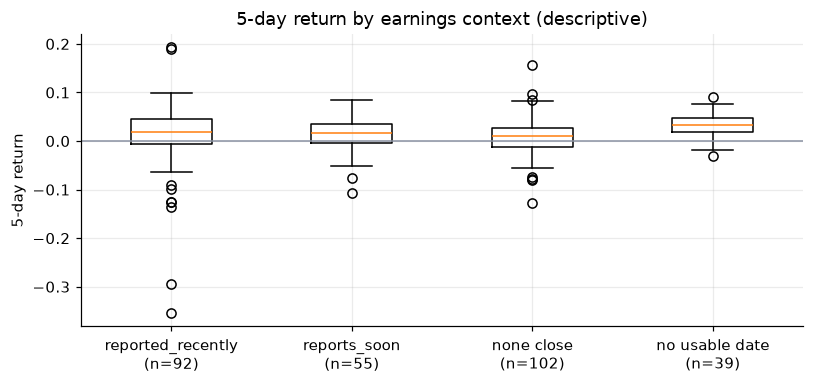

In [7]:
lab = s.earnings_label.where(s.earnings_label != "none", np.where(s.earnings_last.isna(), "no usable date", "none close"))
s["earn_group"] = lab
order = ["reported_recently", "reports_soon", "none close", "no usable date"]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.boxplot([s.loc[s.earn_group == k, "ret_5d"].dropna() for k in order], tick_labels=[f"{k}\n(n={int((s.earn_group == k).sum())})" for k in order])
ax.axhline(0, color=GREY, lw=1); ax.set_ylabel("5-day return"); ax.set_title("5-day return by earnings context (descriptive)")
plt.tight_layout(); plt.savefig("figures/eda_earnings.png"); plt.show()
print(s.groupby("earn_group").ret_5d.agg(["count", "median"]).round(3))

## 7. How do the screen's measures move together?
**Intuition.** Metrics that are strongly correlated carry the same information, so adding another one adds little.

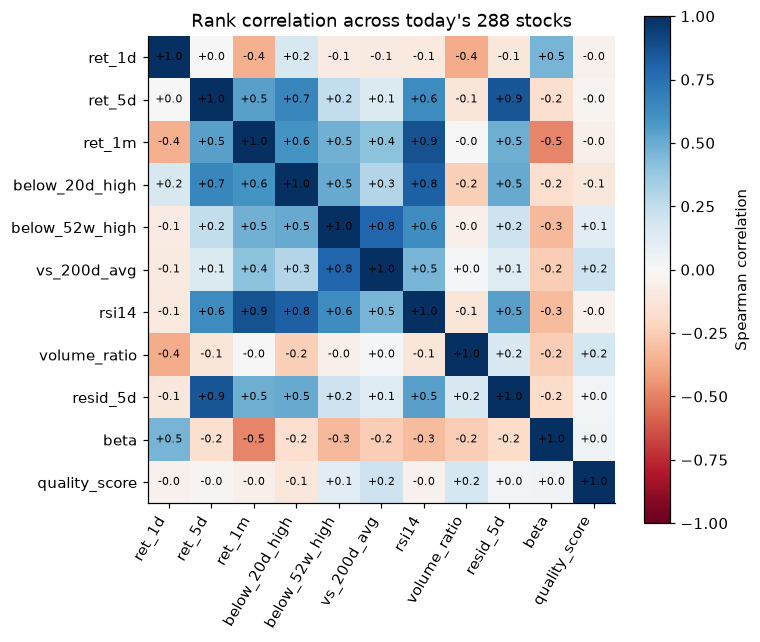

In [8]:
cols = ["ret_1d", "ret_5d", "ret_1m", "below_20d_high", "below_52w_high", "vs_200d_avg", "rsi14", "volume_ratio", "resid_5d", "beta", "quality_score"]
cm = s[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right"); ax.set_yticks(range(len(cols)), cols); ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j, i, f"{cm.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Spearman correlation"); ax.set_title("Rank correlation across today's 288 stocks")
plt.tight_layout(); plt.savefig("figures/eda_correlation.png"); plt.show()

## 8. Your watchlist: last year of prices, rebased to 100
**Intuition.** Rebasing to 100 shows relative performance regardless of price level. Prices are in each stock's own currency, so only the *shape* is comparable.

{'AMD': 195.2, 'ASML.AS': 157.4, 'NESTE.HE': 156.6, 'NVDA': 110.9}


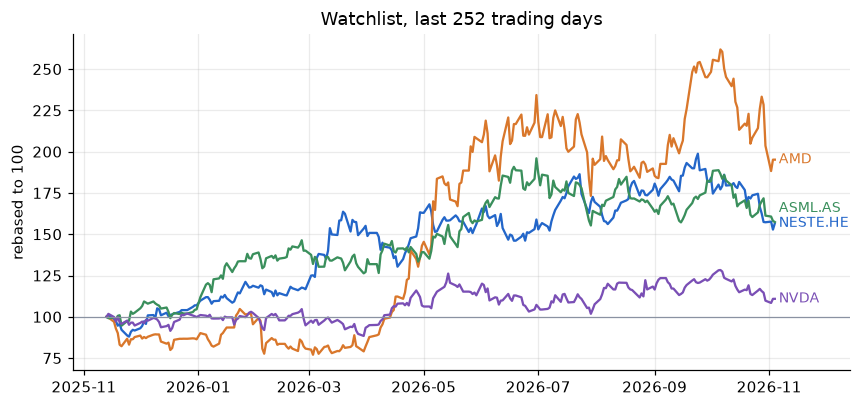

In [9]:
px = pd.read_csv("data/prices_daily.csv.gz", parse_dates=["date"])
watch = ["NESTE.HE", "AMD", "ASML.AS", "NVDA"]
wide = px[px.ticker.isin(watch)].pivot(index="date", columns="ticker", values="close").dropna(how="all").ffill().tail(252)   # carry the last close over other markets' holidays
reb = wide / wide.bfill().iloc[0] * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
for t, c in zip(watch, [BLUE, ORANGE, "#3a8f5c", "#7a4fb5"]):
    ax.plot(reb.index, reb[t], color=c, lw=1.5)
ends = reb.iloc[-1].sort_values()
last_y = -1e9
for t, c in zip(watch, [BLUE, ORANGE, "#3a8f5c", "#7a4fb5"]):
    pass
for t in ends.index:
    y = max(ends[t], last_y + 9); last_y = y
    ax.text(reb.index[-1], y, " " + t, color=dict(zip(watch, [BLUE, ORANGE, "#3a8f5c", "#7a4fb5"]))[t], fontsize=9, va="center")
ax.axhline(100, color=GREY, lw=0.8); ax.set_ylabel("rebased to 100"); ax.set_title("Watchlist, last 252 trading days"); ax.set_xlim(right=reb.index[-1] + pd.Timedelta(days=40))
plt.tight_layout(); plt.savefig("figures/eda_watchlist.png"); plt.show()
print(reb.iloc[-1].round(1).to_dict())

## 9. History of the dip rule (descriptive; read the report before drawing conclusions)
**Intuition.** An *event study* asks: after a stock met the dip rule, what happened over the next 21 trading days, compared with what the other stocks did over the same
window? **Formula.** `excess = fwd21 - ew21`, where `ew21` is the mean 21-day return of all other stocks signalling on the same date.

**How to read it.** The histogram shows the spread; the report gives confidence intervals that account for events clustering in the same months (the
out-of-sample intervals include zero). Today's constituents only, so survivorship bias flatters dip-buying in any such history.

events by year (all periods):
{2010: 530, 2011: 720, 2012: 427, 2013: 270, 2014: 342, 2015: 521, 2016: 508, 2017: 193, 2018: 610, 2019: 369, 2020: 855, 2021: 490, 2022: 945, 2023: 457, 2024: 497, 2025: 590, 2026: 575}
The sample mean is not a result: see data/backtest_171stocks_report.md for month-clustered 90% intervals (they include zero out of sample).


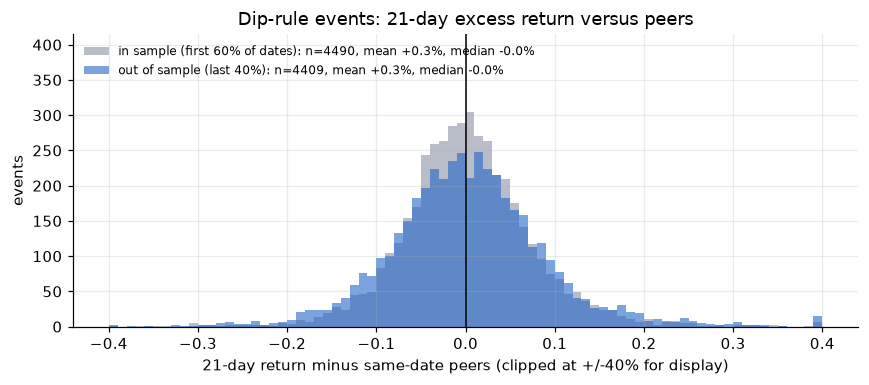

In [10]:
ev = pd.read_csv("data/backtest_events_171stocks.csv.gz", parse_dates=["date"])
v1 = ev[(ev.ev_V1_price_only) & ev.period21.isin(["IS", "OOS"]) & ev.fwd21.notna() & ev.ew21.notna() & ~ev.suspect21.fillna(False)].copy()
v1["excess"] = v1.fwd21 - v1.ew21
fig, ax = plt.subplots(figsize=(8, 3.6))
for per, c, lab in [("IS", GREY, "in sample (first 60% of dates)"), ("OOS", BLUE, "out of sample (last 40%)")]:
    x = v1.loc[v1.period21 == per, "excess"]
    ax.hist(x.clip(-0.4, 0.4), bins=np.linspace(-0.4, 0.4, 81), alpha=0.6, color=c, label=f"{lab}: n={len(x)}, mean {x.mean():+.1%}, median {x.median():+.1%}")
ax.axvline(0, color="k", lw=1); ax.set_xlabel("21-day return minus same-date peers (clipped at +/-40% for display)"); ax.set_ylabel("events"); ax.set_ylim(0, ax.get_ylim()[1] * 1.3); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Dip-rule events: 21-day excess return versus peers"); plt.tight_layout(); plt.savefig("figures/eda_events.png"); plt.show()
print("events by year (all periods):"); print(v1.groupby(v1.date.dt.year).size().to_dict())
print("The sample mean is not a result: see data/backtest_171stocks_report.md for month-clustered 90% intervals (they include zero out of sample).")

## 10. Did any price feature show out-of-sample signal? (pre-registered experiment)
Six price-only features were rank-correlated with the 21-day forward return of dip events (market effect removed). Signs were fixed in-sample; the out-of-sample
result is the one test. **All six Holm-adjusted p-values are 1.0**; every interval includes zero. The smallest correlation this sample could resolve is about 0.05 to 0.09, so
"nothing detected" is not "nothing exists".

           feature    n    est     lo    hi     p  p_holm  mde_80
   f1_volume_ratio 4409 -0.004 -0.039 0.031 0.841     1.0   0.053
       f2_mom_12_1 4409  0.006 -0.057 0.064 0.869     1.0   0.092
 f3_volscaled_drop 4409  0.012 -0.028 0.052 0.628     1.0   0.061
f4_days_since_high 4409 -0.005 -0.050 0.043 0.865     1.0   0.070
   f5_realised_vol 4409 -0.001 -0.047 0.051 0.962     1.0   0.074
         f6_dd_52w 4409 -0.017 -0.074 0.041 0.672     1.0   0.087


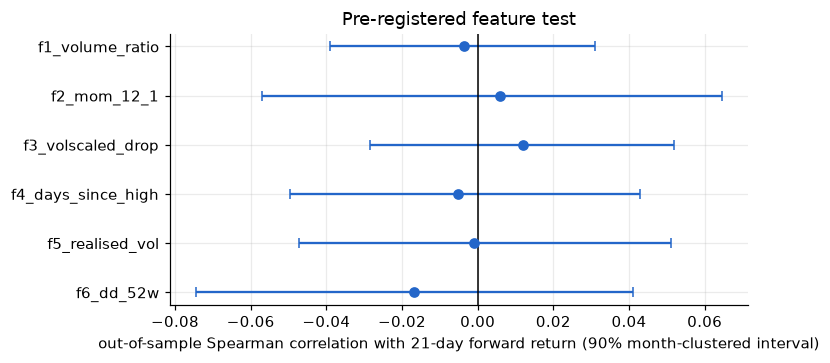

In [11]:
fr = pd.read_csv("data/features_results.csv")
oos = fr[(fr.period == "OOS") & (fr.group == "All") & (fr.stat == "spearman")].copy()
fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(oos))[::-1]
ax.errorbar(oos.est, y, xerr=[oos.est - oos.lo, oos.hi - oos.est], fmt="o", color=BLUE, capsize=3)
ax.axvline(0, color="k", lw=1); ax.set_yticks(y, oos.feature); ax.set_xlabel("out-of-sample Spearman correlation with 21-day forward return (90% month-clustered interval)")
ax.set_title("Pre-registered feature test"); plt.tight_layout(); plt.savefig("figures/eda_features.png"); plt.show()
print(oos[["feature", "n", "est", "lo", "hi", "p", "p_holm", "mde_80"]].round(3).to_string(index=False))

## 11. Things worth asking next (for an assistant or for yourself)
- Which sectors show the most flagged dips today, and is it company-specific (large residuals) or sector-wide (small residuals)?
- For stocks that reported within 5 days, how much of the 5-day move is the earnings reaction versus the market?
- Which flagged stocks have quality scores resting on fewer than 4 checks?
- How does the picture change if the 22 stocks under 20B USD market cap are excluded?

Remember the rules of this project: wording is "screen results", "candidates", "flagged because"; backtest claims need trade counts, costs, a baseline,
an out-of-sample period and confidence intervals; and nothing here is investment advice.